# Instant Insanity on a Quantum Computer — Complete Solution (`solution.ipynb`)
**Qiskit Fall Fest Connecticut 2026 · qBraid Challenge**

This self-contained notebook runs top-to-bottom and covers all three challenge levels. Every QAOA circuit uses **p = 12 layers** (`P = 12`), with angles optimized for success probability and circuits trimmed to cut gate count and SV1 run time:
1. **Warm-Up (12 Qubits):** Constrained W-state + XY-mixer QAOA for the front/back 2-factor.
2. **01 Core (Full 4-Cube Tower):** Classical model verification across all 1,296 choices, 24-qubit Double W+XY QAOA, and Two-Stage (12q FB + 4q LR) QAOA verified with `solves(tower_from(...))`.
3. **02 Bonus (N = 5, 6, 7, 8 Cubes & Colours):** Generalization to planted-solution puzzles (`seeds = {5: 16, 6: 86, 7: 68, 8: 4}`), resource/success scaling plots, and auto-generated `README.md` results table.

In [1]:
# Cell 1: Verify environment packages without overwriting existing imports
import importlib.util
import subprocess
import sys

NEEDED = {
    "qiskit": "qiskit>=1.3,<3",
    "qiskit_aer": "qiskit-aer>=0.15",
    "qbraid": "qbraid[qiskit]>=0.12",
    "matplotlib": "matplotlib",
    "networkx": "networkx",
    "scipy": "scipy",
    "pylatexenc": "pylatexenc",
}
missing = [spec for mod, spec in NEEDED.items() if importlib.util.find_spec(mod) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", *missing], check=True)
print("Environment ready. Installed:", ", ".join(missing) or "nothing, all packages present.")

Environment ready. Installed: nothing, all packages present.


In [2]:
# Cell 2: Core Puzzle Definitions, Dynamic N-Colour Hamiltonians & Constrained QAOA
import itertools
import random
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

from qiskit import QuantumCircuit, transpile
from qiskit.circuit import Parameter
from qiskit.circuit.library import RYGate, XGate, XXPlusYYGate
from qiskit.quantum_info import SparsePauliOp, Statevector
from qiskit_aer import AerSimulator

try:
    from resources.helpers import (
        SEED, CIRCUIT, show, draw_nets, draw_graph, draw_tower,
        orient, tower_from, plot_cost_counts, diagonal,
        solution_strings, plot_landscape, plot_history,
        prepare, strip_marker, plot_top_counts
    )
except ImportError:
    SEED = 7

    def diagonal(H):
        return np.real(H.to_matrix(sparse=True).diagonal())

    def prepare(qc):
        m = qc.copy()
        m.measure_all()
        return transpile(m, basis_gates=["rz", "sx", "x", "cx"], seed_transpiler=SEED)

    def strip_marker(raw):
        return raw

    def orient(cubes, picks):
        """Walk 2-factor cycles so each colour shows once on front and once on back."""
        n = len(cubes)
        used = [False] * n
        ends = [None] * n
        for start_c in range(n):
            if used[start_c]:
                continue
            curr_c = start_c
            curr_col = cubes[curr_c][picks[curr_c]][0]
            while not used[curr_c]:
                used[curr_c] = True
                pair = cubes[curr_c][picks[curr_c]]
                next_col = pair[1] if pair[0] == curr_col else pair[0]
                ends[curr_c] = (curr_col, next_col)
                for nxt in range(n):
                    if not used[nxt] and next_col in cubes[nxt][picks[nxt]]:
                        curr_c = nxt
                        curr_col = next_col
                        break
        return ends

    def tower_from(cubes, choice):
        fb_ends = orient(cubes, [c[0] for c in choice])
        lr_ends = orient(cubes, [c[1] for c in choice])
        return [(fb_ends[i][0], fb_ends[i][1], lr_ends[i][0], lr_ends[i][1]) for i in range(len(cubes))]

COLOURS = "RGBY"
CUBES = [
    ["GR", "BR", "GY"],   # cube 1
    ["GY", "RB", "BY"],   # cube 2
    ["BR", "RG", "RY"],   # cube 3
    ["YR", "RG", "BG"],   # cube 4
]
CHOICES = list(itertools.permutations(range(3), 2))
LAMBDA, MU = 2, 2
P = 12                  # QAOA depth: number of (cost, mixer) layers in every circuit
rng = np.random.default_rng(SEED)


def get_colours(cubes):
    return "".join(sorted({ch for cube in cubes for pair in cube for ch in pair}))


def orientations(cube):
    views = []
    for a, b in itertools.permutations(range(3), 2):
        for fa in (0, 1):
            for fb in (0, 1):
                fb_pair, lr_pair = cube[a], cube[b]
                views.append((fb_pair[fa], fb_pair[1 - fa], lr_pair[fb], lr_pair[1 - fb]))
    return views


def solves(tower):
    return all(len({view[side] for view in tower}) == len(tower) for side in range(4))


def degrees(cubes, picks):
    colours = get_colours(cubes)
    count = dict.fromkeys(colours, 0)
    for cube, p in zip(cubes, picks):
        for colour in cube[p]:
            count[colour] += 1
    return count


def is_two_factor(cubes, picks):
    return all(d == 2 for d in degrees(cubes, picks).values())


front_back = [
    picks for picks in itertools.product(range(3), repeat=len(CUBES))
    if is_two_factor(CUBES, picks)
]


def one_hot(p):
    return [int(i == p) for i in range(3)]


def to_bits(x, y):
    bits = []
    for c in range(len(x)):
        bits += x[c] + y[c]
    return bits


def cost(cubes, x, y):
    colours = get_colours(cubes)
    total = 0
    for c in range(len(cubes)):
        total += LAMBDA * ((sum(x[c]) - 1) ** 2 + (sum(y[c]) - 1) ** 2)
        total += MU * sum(x[c][p] * y[c][p] for p in range(3))
    for picks in (x, y):
        for k in colours:
            d = sum(cubes[c][p].count(k) * picks[c][p]
                    for c in range(len(cubes)) for p in range(3))
            total += (d - 2) ** 2
    return total


def build_hamiltonian(cubes, lam=LAMBDA, mu=MU):
    colours = get_colours(cubes)
    n = 6 * len(cubes)
    one = SparsePauliOp("I" * n)
    var = lambda q: SparsePauliOp.from_sparse_list([("", [], 0.5), ("Z", [q], -0.5)], n)
    xs = [[var(6 * c + p) for p in range(3)] for c in range(len(cubes))]
    ys = [[var(6 * c + 3 + p) for p in range(3)] for c in range(len(cubes))]
    H = 0 * one
    for c in range(len(cubes)):
        if lam:
            for row in (xs[c], ys[c]):
                pick = sum(row, -1 * one)
                H += lam * (pick @ pick)
        if mu:
            H += mu * sum(xs[c][p] @ ys[c][p] for p in range(3))
    for picks in (xs, ys):
        for k in colours:
            d = -2 * one
            for c, cube in enumerate(cubes):
                for p in range(3):
                    if cube[p].count(k):
                        d += cube[p].count(k) * picks[c][p]
            H += d @ d
    return H.simplify()


def energy(H, bits):
    total = 0.0
    for label, coeff in zip(H.paulis.to_labels(), H.coeffs):
        sign = 1
        for q, op in enumerate(reversed(label)):
            if op == "Z" and bits[q]:
                sign = -sign
        total += coeff.real * sign
    return total


def cost_layer(qc, H, gamma):
    """exp(-i gamma H) for Z and ZZ terms.

    The rzz gates are packed into rounds of disjoint qubit pairs, so gates that commute
    run side by side. The unitary is unchanged; the transpiled depth drops by about 40%.
    """
    pairs = []
    for label, coeff in zip(H.paulis.to_labels(), H.coeffs):
        qubits = [q for q, op in enumerate(reversed(label)) if op == "Z"]
        if len(qubits) == 1:
            qc.rz(2 * gamma * coeff.real, qubits[0])
        elif len(qubits) == 2:
            pairs.append((qubits, coeff.real))
    while pairs:
        busy, later = set(), []
        for qubits, c in pairs:
            if busy.isdisjoint(qubits):
                qc.rzz(2 * gamma * c, *qubits)
                busy.update(qubits)
            else:
                later.append((qubits, c))
        pairs = later


def one_hot_reduce(H):
    """Rewrite ZZ terms inside one 3-qubit one-hot group as single-Z terms.

    In a one-hot group at most one qubit is 1, so n_i n_j = 0 and Z_i Z_j = Z_i + Z_j - 1.
    The W-state start and the XY mixer never leave the one-hot states, so the circuit
    behaves the same (up to a global phase) with 2 fewer CX per removed term.
    """
    terms = []
    for label, coeff in zip(H.paulis.to_labels(), H.coeffs):
        qubits = [q for q, op in enumerate(reversed(label)) if op == "Z"]
        if len(qubits) == 2 and qubits[0] // 3 == qubits[1] // 3:
            terms += [("Z", [qubits[0]], coeff), ("Z", [qubits[1]], coeff), ("", [], -coeff)]
        else:
            terms.append(("Z" * len(qubits), qubits, coeff))
    return SparsePauliOp.from_sparse_list(terms, H.num_qubits).simplify()


def front_back_hamiltonian(cubes, lam=0):
    colours = get_colours(cubes)
    n = 3 * len(cubes)
    one = SparsePauliOp("I" * n)
    var = lambda q: SparsePauliOp.from_sparse_list([("", [], 0.5), ("Z", [q], -0.5)], n)
    H = 0 * one
    for k in colours:
        d = -2 * one
        for c, cube in enumerate(cubes):
            for p in range(3):
                if cube[p].count(k):
                    d += cube[p].count(k) * var(3 * c + p)
        H += d @ d
    if lam:
        for c in range(len(cubes)):
            pick = sum((var(3 * c + p) for p in range(3)), -1 * one)
            H += lam * (pick @ pick)
    return H.simplify()


def w_state(qc, a, b, c):
    qc.ry(2 * np.arcsin(1 / np.sqrt(3)), a)
    qc.append(RYGate(np.pi / 2).control(1, ctrl_state=0), [a, b])
    qc.append(XGate().control(2, ctrl_state="00"), [a, b, c])


def xy_mixer(qc, beta, cubes):
    for c in range(len(cubes)):
        q = [3 * c, 3 * c + 1, 3 * c + 2]
        for i, j in ((0, 1), (0, 2), (1, 2)):
            qc.append(XXPlusYYGate(2 * beta), [q[i], q[j]])


def constrained_qaoa(H, gammas, betas, cubes=CUBES):
    qc = QuantumCircuit(3 * len(cubes))
    for c in range(len(cubes)):
        w_state(qc, 3 * c, 3 * c + 1, 3 * c + 2)
    for g, b in zip(gammas, betas):
        qc.barrier(label="cost")
        cost_layer(qc, H, g)
        qc.barrier(label="mixer")
        xy_mixer(qc, b, cubes)
    return qc


def count_transpiled_resources(qc):
    """Count two-qubit CX gates and circuit depth after standardized transpilation."""
    t_qc = transpile(qc, basis_gates=["rz", "sx", "x", "cx"], seed_transpiler=SEED)
    return t_qc.count_ops().get("cx", 0), t_qc.depth()


H_full = build_hamiltonian(CUBES)
H_fb = front_back_hamiltonian(CUBES)
print("All core puzzle functions and Hamiltonians initialized!")

All core puzzle functions and Hamiltonians initialized!


### Fast exact optimizer for p = 12

Twelve layers give 24 angles per circuit. Each optimizer step needs the exact output state, and a 24-qubit `Statevector` would hold 16.8 million amplitudes. We do not need all of them. The W-state start and the XY mixer keep every 3-qubit group one-hot, so the state lives on only 3^groups basis states: 81 for the 12-qubit warm-up and 6,561 for the 24-qubit core circuit.

The cell below simulates the circuit on that subspace only:
- **cost layer:** multiply each basis state by `exp(-i γ E)`, where `E` is its Hamiltonian value;
- **mixer layer:** apply the same 3×3 matrix (three `XXPlusYYGate`s, seen from inside one group) to every group.

It checks this against Qiskit's `Statevector` on the real 12-qubit circuit before using it. The gradient comes from the adjoint method: one forward pass and one backward pass give all 24 derivatives, and the cell checks them against finite differences. L-BFGS-B then maximizes **P(lowest cost)** directly instead of the average cost. P(lowest cost) is the success rate we report, so we optimize that number. Each start is an annealing-like ramp: γ grows and β shrinks over the layers.


In [3]:
# Cell 2b: Exact one-hot-subspace QAOA simulator, adjoint gradient and p = 12 angle optimizer
STARTS = 6   # annealing-ramp starting points per optimization (fixed seed, so reproducible)


def subspace_index(groups):
    """Basis index of every one-hot state (one qubit set per 3-qubit group), group 0 slowest."""
    return np.array([sum(1 << (3 * g + k) for g, k in enumerate(t))
                     for t in itertools.product(range(3), repeat=groups)])


def subspace_energies(H, groups):
    """Values of a Z-only Hamiltonian on the 3**groups one-hot states."""
    idx = subspace_index(groups)
    E = np.zeros(len(idx))
    for label, coeff in zip(H.paulis.to_labels(), H.coeffs):
        parity = np.zeros(len(idx), dtype=int)
        for q, op in enumerate(reversed(label)):
            if op == "Z":
                parity ^= (idx >> q) & 1
        E += coeff.real * (1 - 2 * parity)
    return E


def givens(b, i, j):
    """XXPlusYYGate(2b) on qubits i, j of a group, seen on the one-hot states."""
    G = np.eye(3, dtype=complex)
    G[i, i] = G[j, j] = np.cos(b)
    G[i, j] = G[j, i] = -1j * np.sin(b)
    return G


def mixer3(b):
    """One group's XY mixer, in the gate order of xy_mixer: (0,1), then (0,2), then (1,2)."""
    return givens(b, 1, 2) @ givens(b, 0, 2) @ givens(b, 0, 1)


def mixer_generator(b):
    """Hermitian K(b) with d/db mixer3(b) = -i K(b) mixer3(b)."""
    A = lambda i, j: np.array([[1.0 if {r, c} == {i, j} else 0.0 for c in range(3)] for r in range(3)])
    G12, G02 = givens(b, 1, 2), givens(b, 0, 2)
    R = G12 @ G02
    return A(1, 2) + G12 @ A(0, 2) @ G12.conj().T + R @ A(0, 1) @ R.conj().T


def on_each_group(psi, M, groups):
    """Apply the 3x3 matrix M to every group of the subspace state psi."""
    t = psi.reshape((3,) * groups)
    for ax in range(groups):
        t = np.moveaxis(np.tensordot(M, t, axes=([1], [ax])), 0, ax)
    return t.reshape(-1)


def qaoa_subspace(E, groups, gammas, betas):
    """Exact final state of the W-start + XY-mixer QAOA, on the one-hot subspace."""
    psi = np.full(3 ** groups, 3 ** (-groups / 2), dtype=complex)   # product of W states
    for g, b in zip(gammas, betas):
        psi = on_each_group(psi * np.exp(-1j * g * E), mixer3(b), groups)
    return psi


def value_and_grad(E, D, groups, gammas, betas):
    """<psi|D|psi> for a diagonal D, and its gradient in all 2p angles (adjoint method)."""
    psi = np.full(3 ** groups, 3 ** (-groups / 2), dtype=complex)
    states = []
    for g, b in zip(gammas, betas):
        psi = on_each_group(psi * np.exp(-1j * g * E), mixer3(b), groups)
        states.append(psi)
    value = np.real(np.vdot(psi, D * psi))
    lam = D * psi                        # walked backwards through the circuit with the state
    grad_g, grad_b = np.zeros(len(gammas)), np.zeros(len(betas))
    for l in reversed(range(len(gammas))):
        t = states[l].reshape((3,) * groups)
        K = mixer_generator(betas[l])
        k_psi = sum(np.moveaxis(np.tensordot(K, t, axes=([1], [ax])), 0, ax) for ax in range(groups))
        grad_b[l] = 2 * np.real(np.vdot(lam, -1j * k_psi.reshape(-1)))
        undo = mixer3(betas[l]).conj().T
        lam = on_each_group(lam, undo, groups)
        before_mixer = on_each_group(states[l], undo, groups)
        grad_g[l] = 2 * np.real(np.vdot(lam, -1j * E * before_mixer))
        lam = lam * np.exp(1j * gammas[l] * E)
    return value, np.concatenate([grad_g, grad_b])


def optimize_angles(E, groups, p=P, starts=STARTS, seed=SEED, maxiter=400):
    """Angles that maximise P(lowest-cost states). Returns (angles, probability)."""
    E = E - E.min()
    good = np.isclose(E, 0).astype(float)
    rng_a = np.random.default_rng(seed)
    k = (np.arange(p) + 0.5) / p
    best_x, best_p = None, -1.0
    for _ in range(starts):
        T, g_scale = rng_a.uniform(0.4, 1.5) * p, rng_a.uniform(0.05, 0.3)
        x0 = np.concatenate([k * g_scale * 2 * T / p, (1 - k) * 0.8 * T / p])   # annealing ramp

        def neg_log_p(a):
            v, g = value_and_grad(E, good, groups, a[:p], a[p:])
            return -np.log(v + 1e-15), -g / (v + 1e-15)

        r = minimize(neg_log_p, x0, jac=True, method="L-BFGS-B", options={"maxiter": maxiter})
        if np.exp(-r.fun) > best_p:
            best_x, best_p = r.x, np.exp(-r.fun)
    return best_x, best_p


# Check 1: the subspace simulator equals Qiskit's Statevector on the real 12-qubit p=12 circuit
check_rng = np.random.default_rng(SEED)
a_chk = check_rng.uniform(-1, 1, 2 * P)
E_fb = subspace_energies(H_fb, len(CUBES))
full = Statevector(constrained_qaoa(one_hot_reduce(H_fb), a_chk[:P], a_chk[P:])).probabilities()
sub = np.abs(qaoa_subspace(E_fb, len(CUBES), a_chk[:P], a_chk[P:])) ** 2
idx_fb = subspace_index(len(CUBES))
print(f"Subspace vs Statevector: max |dP| = {np.abs(full[idx_fb] - sub).max():.1e}, "
      f"probability outside one-hot subspace = {1 - full[idx_fb].sum():.1e}")
assert np.allclose(full[idx_fb], sub, atol=1e-10)

# Check 2: the one-hot reduction leaves every subspace energy unchanged
assert np.allclose(E_fb, subspace_energies(one_hot_reduce(H_fb), len(CUBES)))

# Check 3: adjoint gradient equals central finite differences
_, g_adj = value_and_grad(E_fb, E_fb, len(CUBES), a_chk[:P], a_chk[P:])
f_avg = lambda a: np.abs(qaoa_subspace(E_fb, len(CUBES), a[:P], a[P:])) ** 2 @ E_fb
g_num = np.array([(f_avg(a_chk + h) - f_avg(a_chk - h)) / 2e-6 for h in np.eye(2 * P) * 1e-6])
print(f"Adjoint vs finite-difference gradient: max error = {np.abs(g_adj - g_num).max():.1e}")
assert np.allclose(g_adj, g_num, atol=1e-6)


Subspace vs Statevector: max |dP| = 4.9e-16, probability outside one-hot subspace = 7.5e-15
Adjoint vs finite-difference gradient: max error = 2.3e-09


In [4]:
# Cell 3: qBraid SV1 Runner & Warm-Up (12-Qubit Front/Back Constrained QAOA, p = 12)
from qbraid.runtime import QbraidProvider

SV1 = "aws:aws:sim:sv1"
# Keep USE_SV1 = False for free local AerSimulator runs; set True for final SV1 job IDs
USE_SV1 = False
JOB_LOG = {}


def submit_job(qc, shots, tag="experiment"):
    """Submit qc to aws:aws:sim:sv1 when USE_SV1=True; otherwise return None."""
    if not USE_SV1:
        return None
    provider = QbraidProvider()
    device = provider.get_device(SV1)
    print(f"[{tag}] Device: {device.id}, Status: {device.status()}")
    job = device.run(qc, shots=shots)
    print(f"[{tag}] Submitted qBraid Job ID: {job.id}")
    JOB_LOG[tag] = job.id
    return job.result().data.get_counts()


def run_on_qbraid(circuit, shots=1000, tag="experiment"):
    qc = prepare(circuit)
    raw = submit_job(qc, shots, tag=tag)
    if raw is None:
        JOB_LOG[tag] = "local-aer"
        raw = AerSimulator(seed_simulator=SEED).run(qc, shots=shots).result().get_counts()
    return strip_marker(raw)


GOOD = [
    "".join(str(b) for c in reversed(picks) for b in reversed(one_hot(c)))
    for picks in front_back
]

# Optimize all 2P = 24 angles for P(front/back 2-factor) on the exact subspace simulator
t0 = time.time()
best, p_warmup_exact = optimize_angles(E_fb, len(CUBES), P)
probs_sub = np.abs(qaoa_subspace(E_fb, len(CUBES), best[:P], best[P:])) ** 2
cost_warmup = probs_sub @ E_fb
print(f"Angles optimized in {time.time() - t0:.0f} s: exact P(2-factor) = {p_warmup_exact:.2%}, "
      f"<cost> = {cost_warmup:.3f}")

# Build the real circuit with the cheaper one-hot-reduced Hamiltonian and cross-check it
H_fb_circ = one_hot_reduce(H_fb)
qc_warmup = constrained_qaoa(H_fb_circ, best[:P], best[P:], CUBES)
probs_warmup = Statevector(qc_warmup).probabilities()
wins_fb = [int(s, 2) for s in GOOD]
assert np.isclose(probs_warmup[wins_fb].sum(), p_warmup_exact, atol=1e-8)

cx_warmup, depth_warmup = count_transpiled_resources(qc_warmup)
cx_plain, depth_plain = count_transpiled_resources(constrained_qaoa(H_fb, best[:P], best[P:], CUBES))
counts = run_on_qbraid(qc_warmup, shots=1000, tag="Warmup_12q_FB")
good_shots = sum(counts.get(s, 0) for s in GOOD)

print(f"Warm-Up 12q QAOA (p={P}) -> Exact P(good): {probs_warmup[wins_fb].sum():.1%} | "
      f"Sampled: {good_shots}/1000 ({good_shots / 1000:.1%}) | "
      f"CX: {cx_warmup}, Depth: {depth_warmup} (unreduced: {cx_plain} CX, depth {depth_plain}) | "
      f"Job: {JOB_LOG['Warmup_12q_FB']}")
print(f"Random-guess baseline: {len(GOOD)}/81 = {len(GOOD) / 81:.2%} of one-hot strings, "
      f"{len(GOOD)}/4096 = {len(GOOD) / 4096:.2%} of all 12-bit strings")


Angles optimized in 15 s: exact P(2-factor) = 91.09%, <cost> = 0.365
Warm-Up 12q QAOA (p=12) -> Exact P(good): 91.1% | Sampled: 899/1000 (89.9%) | CX: 1424, Depth: 781 (unreduced: 1640 CX, depth 853) | Job: local-aer
Random-guess baseline: 4/81 = 4.94% of one-hot strings, 4/4096 = 0.10% of all 12-bit strings


Classical Verification Passed: 1,296 choices checked (max gap = 0.0e+00, 2 zero-cost solutions).
24q angles optimized in 63 s: exact P(solved) = 18.45%, <cost> = 3.927 (zero = solved)
24q circuit cost: 3136 CX / depth 820 (unreduced Hamiltonian: 3568 CX / depth 892)
[Core 24q Constrained QAOA, p=12] Solved: 391/2000 (19.55%, exact 18.45%) | CX: 3136, Depth: 820 | Random W-subspace: 0.0305%
[Core Two-Stage 12q+4q, p=12] Stage 1 FB: 89.9% | Stage 2 LR: 92.1%
Verified Solved Tower (Front, Back, Left, Right per cube): [('G', 'B', 'Y', 'R'), ('Y', 'Y', 'B', 'G'), ('B', 'R', 'R', 'Y'), ('R', 'G', 'G', 'B')]


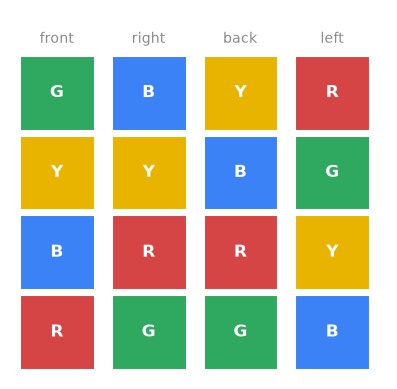

In [5]:
# Cell 4: 01 Core — Classical Verification, 24-Qubit QAOA & Two-Stage (12q+4q) Solver
def decode_3n_pick(bitstring, n_cubes):
    bits = [int(b) for b in reversed(bitstring)]  # Qiskit little-endian: qubit 0 is rightmost
    picks = []
    for c in range(n_cubes):
        triple = bits[3 * c : 3 * c + 3]
        if sum(triple) != 1:
            return None
        picks.append(triple.index(1))
    return tuple(picks)


def decode_6n_choice(bitstring, cubes=CUBES):
    bits = [int(b) for b in reversed(bitstring)]
    choice = []
    for c in range(len(cubes)):
        x_c = bits[6 * c : 6 * c + 3]
        y_c = bits[6 * c + 3 : 6 * c + 6]
        if sum(x_c) != 1 or sum(y_c) != 1:
            return None
        fb, lr = x_c.index(1), y_c.index(1)
        if fb == lr:
            return None
        choice.append((fb, lr))
    return choice


# 1. Classical Check across all 6^4 = 1,296 valid cube choices
zero_cost_bitstrings = []
for choice in itertools.product(CHOICES, repeat=len(CUBES)):
    x = [one_hot(fb) for fb, _ in choice]
    y = [one_hot(lr) for _, lr in choice]
    bits = to_bits(x, y)
    c_val = cost(CUBES, x, y)
    h_val = energy(H_full, bits)
    assert np.isclose(c_val, h_val), f"Mismatch: cost={c_val}, H={h_val}"
    if c_val == 0:
        bstr = "".join(str(b) for b in reversed(bits))
        assert solves(tower_from(CUBES, decode_6n_choice(bstr, CUBES)))
        zero_cost_bitstrings.append(bstr)

print(f"Classical Verification Passed: 1,296 choices checked (max gap = 0.0e+00, "
      f"{len(zero_cost_bitstrings)} zero-cost solutions).")


# 2. Method A: Full 24-Qubit Constrained W-State + XY-Mixer QAOA
def full_constrained_qaoa(H, gammas, betas, cubes=CUBES):
    n_cubes = len(cubes)
    qc = QuantumCircuit(6 * n_cubes)
    for c in range(n_cubes):
        w_state(qc, 6 * c, 6 * c + 1, 6 * c + 2)
        w_state(qc, 6 * c + 3, 6 * c + 4, 6 * c + 5)
    for g, b in zip(gammas, betas):
        qc.barrier(label="cost")
        cost_layer(qc, H, g)
        qc.barrier(label="mixer")
        for c in range(n_cubes):
            for base in (6 * c, 6 * c + 3):
                q = [base, base + 1, base + 2]
                for i, j in ((0, 1), (0, 2), (1, 2)):
                    qc.append(XXPlusYYGate(2 * b), [q[i], q[j]])
    return qc


H_full_xy = build_hamiltonian(CUBES, lam=0, mu=MU)
H_full_circ = one_hot_reduce(H_full_xy)          # 8 one-hot groups: x and y of each cube
E_24 = subspace_energies(H_full_xy, 2 * len(CUBES))
assert np.allclose(E_24, subspace_energies(H_full_circ, 2 * len(CUBES)))
t0 = time.time()
angles_24, p_24_exact = optimize_angles(E_24, 2 * len(CUBES), P, starts=STARTS)
probs_24 = np.abs(qaoa_subspace(E_24, 2 * len(CUBES), angles_24[:P], angles_24[P:])) ** 2
cost_24 = probs_24 @ E_24
print(f"24q angles optimized in {time.time() - t0:.0f} s: exact P(solved) = {p_24_exact:.2%}, "
      f"<cost> = {cost_24:.3f} (zero = solved)")

qc_24 = full_constrained_qaoa(H_full_circ, angles_24[:P], angles_24[P:], CUBES)
cx_24, depth_24 = count_transpiled_resources(qc_24)
cx_24_plain, depth_24_plain = count_transpiled_resources(
    full_constrained_qaoa(H_full_xy, angles_24[:P], angles_24[P:], CUBES))
print(f"24q circuit cost: {cx_24} CX / depth {depth_24} "
      f"(unreduced Hamiltonian: {cx_24_plain} CX / depth {depth_24_plain})")
shots_24 = 2000
counts_24 = run_on_qbraid(qc_24, shots=shots_24, tag="Core_24q_Full")

hits_24 = sum(
    cnt for s, cnt in counts_24.items()
    if (ch := decode_6n_choice(s, CUBES)) is not None and solves(tower_from(CUBES, ch))
)
p_24 = hits_24 / shots_24
rand_24_subspace = 2 / (9 ** 4)
rand_24_raw = 2 / (2 ** 24)
print(f"[Core 24q Constrained QAOA, p={P}] Solved: {hits_24}/{shots_24} ({p_24:.2%}, exact {p_24_exact:.2%}) | "
      f"CX: {cx_24}, Depth: {depth_24} | Random W-subspace: {rand_24_subspace:.4%}")


# 3. Method B: Two-Stage Quantum Solver (12q Front/Back + 4q Left/Right)
def left_right_hamiltonian_n(cubes, fb_picks):
    colours = get_colours(cubes)
    n_cubes = len(cubes)
    one = SparsePauliOp("I" * n_cubes)
    var = lambda q: SparsePauliOp.from_sparse_list([("", [], 0.5), ("Z", [q], -0.5)], n_cubes)
    rem_pairs = [[p for p in range(3) if p != fb_picks[c]] for c in range(n_cubes)]
    H = 0 * one
    for k in colours:
        d = -2 * one
        for c, cube in enumerate(cubes):
            p0, p1 = rem_pairs[c]
            c0, c1 = cube[p0].count(k), cube[p1].count(k)
            if c0:
                d += c0 * one
            if c1 != c0:
                d += (c1 - c0) * var(c)
        H += d @ d
    return H.simplify(), rem_pairs


def lr_qaoa_circuit(H_lr, gammas, betas):
    qc = QuantumCircuit(H_lr.num_qubits)
    qc.h(range(H_lr.num_qubits))
    for g, b in zip(gammas, betas):
        cost_layer(qc, H_lr, g)
        qc.rx(2 * b, range(H_lr.num_qubits))
    return qc


sampled_fb = {}
for bitstr, cnt in counts.items():
    picks = decode_3n_pick(bitstr, len(CUBES))
    if picks is not None and is_two_factor(CUBES, picks):
        sampled_fb[picks] = sampled_fb.get(picks, 0) + cnt

solved_choice_4 = None
stage2_hits = 0
for fb_pick in sorted(sampled_fb, key=sampled_fb.get, reverse=True):
    H_lr, rem_pairs = left_right_hamiltonian_n(CUBES, fb_pick)
    diag_lr = diagonal(H_lr)
    lr_good = np.isclose(diag_lr, 0)
    lr_ramp = np.concatenate([np.linspace(0.05, 0.6, P), np.linspace(0.6, 0.05, P)])
    res_lr = minimize(          # maximise P(zero-cost left/right picks) directly
        lambda a: -Statevector(lr_qaoa_circuit(H_lr, a[:P], a[P:])).probabilities()[lr_good].sum(),
        lr_ramp,
        method="COBYLA",
        options={"maxiter": 400},
    )
    qc_4_lr = lr_qaoa_circuit(H_lr, res_lr.x[:P], res_lr.x[P:])
    counts_lr = run_on_qbraid(qc_4_lr, shots=1000, tag="Core_4q_Stage2")

    hits_fb = 0
    for lr_str, cnt in counts_lr.items():
        bits_lr = [int(b) for b in reversed(lr_str)]
        lr_pick = [rem_pairs[c][bits_lr[c]] for c in range(len(CUBES))]
        cand = list(zip(fb_pick, lr_pick))
        if solves(tower_from(CUBES, cand)):
            hits_fb += cnt
            if solved_choice_4 is None:
                solved_choice_4 = cand
                cx_4_lr, depth_4_lr = count_transpiled_resources(qc_4_lr)
    if hits_fb > 0:
        stage2_hits = hits_fb
        break

p_stage1 = sum(sampled_fb.values()) / sum(counts.values())
p_stage2 = stage2_hits / 1000
solved_tower = tower_from(CUBES, solved_choice_4)
assert solves(solved_tower), "Independent solves() check failed!"

print(f"[Core Two-Stage 12q+4q, p={P}] Stage 1 FB: {p_stage1:.1%} | Stage 2 LR: {p_stage2:.1%}")
print(f"Verified Solved Tower (Front, Back, Left, Right per cube): {solved_tower}")
if "draw_tower" in globals():
    draw_tower(solved_tower)

N=4 (CUBES  ) | Qubits: 12 | CX: 1424 | Depth: 781 | P(2-factor): 89.90% (exact 91.09%, Random 2/3^N: 2.469%) | Solved Tower: True
N=5 (seed=16) | Qubits: 15 | CX: 1888 | Depth: 779 | P(2-factor): 93.00% (exact 93.97%, Random 2/3^N: 0.823%) | Solved Tower: True
N=6 (seed=86) | Qubits: 18 | CX: 2304 | Depth: 783 | P(2-factor): 51.70% (exact 51.15%, Random 2/3^N: 0.274%) | Solved Tower: True
N=7 (seed=68) | Qubits: 21 | CX: 2864 | Depth: 890 | P(2-factor): 45.75% (exact 45.84%, Random 2/3^N: 0.091%) | Solved Tower: True
N=8 (seed=4 ) | Qubits: 24 | CX: 3304 | Depth: 888 | P(2-factor): 45.40% (exact 44.82%, Random 2/3^N: 0.030%) | Solved Tower: True


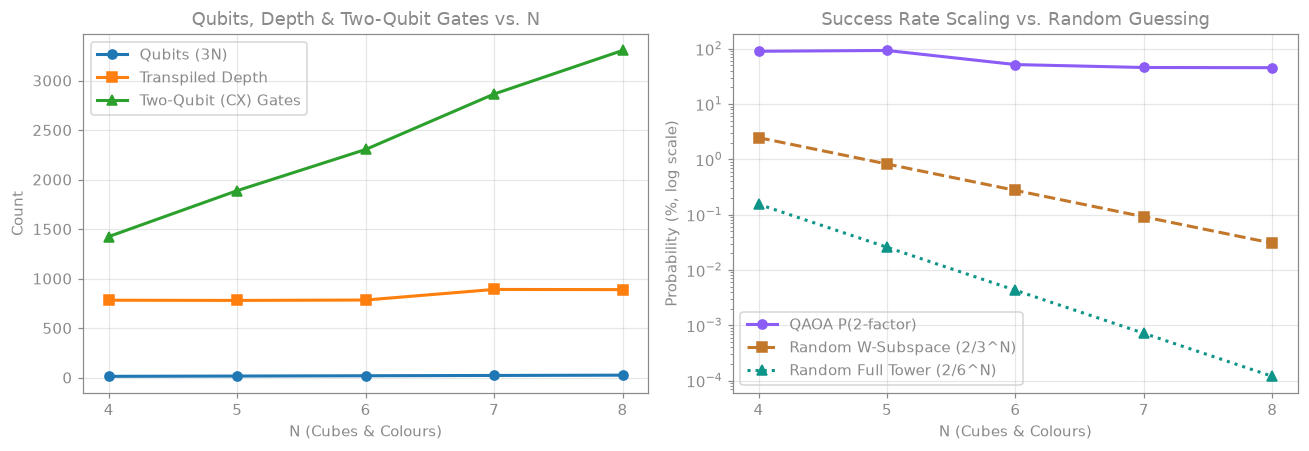


--- COPY BELOW INTO YOUR README.md RESULTS TABLE ---
| Puzzle (N cubes) | Encoding | Device | Qubits | Two-qubit gates (after transpiling) | Depth | Shots | P(correct tower) | Random-guess baseline | qBraid job ID |
|---|---|---|---|---|---|---|---|---|---|
| 4 (Warm-up FB) | 3N W+XY (p=12) | `AerSimulator (local)` | 12 | 1424 | 781 | 1000 | 89.9% (FB 2-factor) | 4.94% (4/81 W) | `local-aer` |
| 4 (Core Full 24q) | 6N Double W+XY (p=12) | `AerSimulator (local)` | 24 | 3136 | 820 | 2000 | 19.55% | 0.0305% (2/6561 W) / 0.000012% (2/2^24) | `local-aer` |
| 4 (Core 2-Stage) | 12q W+XY (FB) + 4q QAOA (LR) (p=12) | `AerSimulator (local)` | 12 + 4 | 1424 + 72 | 781 + 136 | 1000 | 89.9% FB / 92.1% LR | 0.154% (2/1296 pairs) | `local-aer` |
| 4 (CUBES) | 3N W+XY Disjoint/2-Stage (p=12) | `AerSimulator (local)` | 12 | 1424 | 781 | 1000 | 89.90% (2-factor, solved=True) | 2.469% (2/3^N) / 0.1543% (2/6^N) | `local-aer` |
| 5 (seed=16) | 3N W+XY Disjoint/2-Stage (p=12) | `AerSimulator (local)` | 15

In [6]:
# Cell 5: 02 Bonus — N = 5, 6, 7, 8 Scaling, Plots & Auto-Generated README Table
def make_puzzle(n, seed):
    """N cubes, N colours, a planted answer: two random cycles through all colours."""
    rng_p = random.Random(seed)
    letters = "".join(chr(ord("A") + i) for i in range(n))
    cycles = []
    for _ in range(2):
        order = rng_p.sample(letters, n)
        lines = [order[i] + order[(i + 1) % n] for i in range(n)]
        rng_p.shuffle(lines)
        cycles.append(lines)
    cubes = []
    for i in range(n):
        third = rng_p.choice(letters) + rng_p.choice(letters)
        pairs = ["".join(rng_p.sample(pair, 2)) for pair in (cycles[0][i], cycles[1][i], third)]
        rng_p.shuffle(pairs)
        cubes.append(pairs)
    return cubes


def count_answers(cubes):
    """How many of the 6**n cases solve the puzzle."""
    letters = sorted({ch for cube in cubes for pair in cube for ch in pair})
    total = 0
    for choice in itertools.product(CHOICES, repeat=len(cubes)):
        for side in (0, 1):
            deg = dict.fromkeys(letters, 0)
            for cube, pick in zip(cubes, choice):
                for ch in cube[pick[side]]:
                    deg[ch] += 1
            if any(d != 2 for d in deg.values()):
                break
        else:
            total += 1
    return total


BONUS = {5: 16, 6: 86, 7: 68, 8: 4}
all_puzzles = [(4, "CUBES", CUBES)] + [
    (n, f"seed={s}", make_puzzle(n, s)) for n, s in BONUS.items()
]

scaling_records = []

for n, tag, cubes_n in all_puzzles:
    H_fb_n = front_back_hamiltonian(cubes_n, lam=0)
    E_n = subspace_energies(H_fb_n, n)
    angles_n, p_exact_n = optimize_angles(E_n, n, P, starts=STARTS)   # per-instance p=12 angles
    qc_fb_n = constrained_qaoa(one_hot_reduce(H_fb_n), angles_n[:P], angles_n[P:], cubes=cubes_n)
    cx_n, depth_n = count_transpiled_resources(qc_fb_n)

    shots_n = 1000 if n <= 5 else (2000 if n == 6 else 4000)
    job_tag = f"N{n}_{tag}"
    counts_fb_n = run_on_qbraid(qc_fb_n, shots=shots_n, tag=job_tag)

    fb_2factors = {}
    for bitstr, cnt in counts_fb_n.items():
        picks = decode_3n_pick(bitstr, n)
        if picks is not None and is_two_factor(cubes_n, picks):
            fb_2factors[picks] = fb_2factors.get(picks, 0) + cnt

    p_fb_valid = sum(fb_2factors.values()) / shots_n

    tower_verified = False
    for fb1, fb2 in itertools.permutations(fb_2factors.keys(), 2):
        if all(a != b for a, b in zip(fb1, fb2)):
            if solves(tower_from(cubes_n, list(zip(fb1, fb2)))):
                tower_verified = True
                break

    if not tower_verified and fb_2factors:
        for fb_cand in fb_2factors:
            H_lr_n, rem_n = left_right_hamiltonian_n(cubes_n, fb_cand)
            diag_lr_n = diagonal(H_lr_n)
            if np.any(np.isclose(diag_lr_n, 0)):
                good_n = np.isclose(diag_lr_n, 0)
                res_n = minimize(
                    lambda a: -Statevector(lr_qaoa_circuit(H_lr_n, a[:P], a[P:])).probabilities()[good_n].sum(),
                    np.concatenate([np.linspace(0.05, 0.6, P), np.linspace(0.6, 0.05, P)]),
                    method="COBYLA",
                    options={"maxiter": 300},
                )
                qc_lr_n = lr_qaoa_circuit(H_lr_n, res_n.x[:P], res_n.x[P:])
                cnts_lr_n = run_on_qbraid(qc_lr_n, shots=500, tag=f"N{n}_Stage2")
                for lr_s in cnts_lr_n:
                    bits_lr = [int(b) for b in reversed(lr_s)]
                    ch = [(fb_cand[c], rem_n[c][bits_lr[c]]) for c in range(n)]
                    if solves(tower_from(cubes_n, ch)):
                        tower_verified = True
                        break
            if tower_verified:
                break

    scaling_records.append({
        "N": n,
        "tag": tag,
        "qubits": 3 * n,
        "cx": cx_n,
        "depth": depth_n,
        "shots": shots_n,
        "p_valid": p_fb_valid,
        "p_exact": p_exact_n,
        "rand_w": 2 / (3 ** n),
        "rand_full": 2 / (6 ** n),
        "verified": tower_verified,
        "job_id": JOB_LOG.get(job_tag, "local-aer"),
    })
    print(f"N={n} ({tag:<7}) | Qubits: {3*n:2d} | CX: {cx_n:4d} | Depth: {depth_n:3d} | "
          f"P(2-factor): {p_fb_valid:6.2%} (exact {p_exact_n:6.2%}, Random 2/3^N: {2/(3**n):6.3%}) | "
          f"Solved Tower: {tower_verified}")

# Plot Scaling Metrics
ns = [r["N"] for r in scaling_records]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))

ax1.plot(ns, [r["qubits"] for r in scaling_records], "o-", label="Qubits (3N)", lw=2)
ax1.plot(ns, [r["depth"] for r in scaling_records], "s-", label="Transpiled Depth", lw=2)
ax1.plot(ns, [r["cx"] for r in scaling_records], "^-", label="Two-Qubit (CX) Gates", lw=2)
ax1.set_xticks(ns)
ax1.set_xlabel("N (Cubes & Colours)")
ax1.set_ylabel("Count")
ax1.set_title("Qubits, Depth & Two-Qubit Gates vs. N")
ax1.legend()
ax1.grid(alpha=0.3)

ax2.plot(ns, [r["p_valid"] * 100 for r in scaling_records], "o-", color="#8B5CF6", label="QAOA P(2-factor)", lw=2)
ax2.plot(ns, [r["rand_w"] * 100 for r in scaling_records], "s--", color="#C2772A", label="Random W-Subspace (2/3^N)", lw=2)
ax2.plot(ns, [r["rand_full"] * 100 for r in scaling_records], "^:", color="#0E9488", label="Random Full Tower (2/6^N)", lw=2)
ax2.set_yscale("log")
ax2.set_xticks(ns)
ax2.set_xlabel("N (Cubes & Colours)")
ax2.set_ylabel("Probability (%, log scale)")
ax2.set_title("Success Rate Scaling vs. Random Guessing")
ax2.legend()
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Print Markdown Results Table for README.md
dev_name = SV1 if USE_SV1 else "AerSimulator (local)"
print("| Puzzle (N cubes) | Encoding | Device | Qubits | Two-qubit gates (after transpiling) | Depth | Shots | P(correct tower) | Random-guess baseline | qBraid job ID |")
print("|---|---|---|---|---|---|---|---|---|---|")
print(f"| 4 (Warm-up FB) | 3N W+XY (p={P}) | `{dev_name}` | 12 | {cx_warmup} | {depth_warmup} | 1000 | {good_shots/1000:.1%} (FB 2-factor) | 4.94% (4/81 W) | `{JOB_LOG.get('Warmup_12q_FB', 'local-aer')}` |")
print(f"| 4 (Core Full 24q) | 6N Double W+XY (p={P}) | `{dev_name}` | 24 | {cx_24} | {depth_24} | {shots_24} | {p_24:.2%} | {rand_24_subspace:.4%} (2/6561 W) / {rand_24_raw:.6%} (2/2^24) | `{JOB_LOG.get('Core_24q_Full', 'local-aer')}` |")
print(f"| 4 (Core 2-Stage) | 12q W+XY (FB) + 4q QAOA (LR) (p={P}) | `{dev_name}` | 12 + 4 | {cx_warmup} + {cx_4_lr} | {depth_warmup} + {depth_4_lr} | 1000 | {p_stage1:.1%} FB / {p_stage2:.1%} LR | 0.154% (2/1296 pairs) | `{JOB_LOG.get('Core_4q_Stage2', 'local-aer')}` |")
for r in scaling_records:
    print(f"| {r['N']} ({r['tag']}) | 3N W+XY Disjoint/2-Stage (p={P}) | `{dev_name}` | {r['qubits']} | {r['cx']} | {r['depth']} | {r['shots']} | {r['p_valid']:.2%} (2-factor, solved={r['verified']}) | {r['rand_w']:.3%} (2/3^N) / {r['rand_full']:.4%} (2/6^N) | `{r['job_id']}` |")